# 🐱🐶 Dog vs Cat Classification using CNN & EfficientNet
- Data loading
- Preprocessing & augmentation
- Simple CNN model
- Pretrained CNN Model: EfficientNet
- Training with callbacks
- Evaluation, confusion matrix, error analysis

## 1. Import Libraries

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import os
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')

print(gpus)

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load Dataset

In [ ]:
!git clone https://github.com/laxmimerit/dog-cat-full-dataset.git

Cloning into 'dog-cat-full-dataset'...
remote: Enumerating objects: 25059, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 25059 (delta 4), reused 6 (delta 2), pack-reused 25048 (from 1)
Receiving objects: 100% (25059/25059), 541.54 MiB | 33.32 MiB/s, done.
Resolving deltas: 100% (21/21), done.
Updating files: 100% (24990/24990), done.


In [ ]:
IMG_SIZE = (160, 160)
BATCH_SIZE = 32
SEED = 42
TRAIN_DATASET_PATH = "/content/dog-cat-full-dataset/data/train"
TEST_DATASET_PATH = "/content/dog-cat-full-dataset/data/test"


train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DATASET_PATH,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names

print()
print(f"Class Names: {class_names}")

Found 19989 files belonging to 2 classes.
Using 15992 files for training.
Found 19989 files belonging to 2 classes.
Using 3997 files for validation.
Found 5000 files belonging to 2 classes.

Class Names: ['cats', 'dogs']


## 3. Normalization & Performance Optimization

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y)).prefetch(AUTOTUNE)
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y)).prefetch(AUTOTUNE)


## 4. Data Augmentation

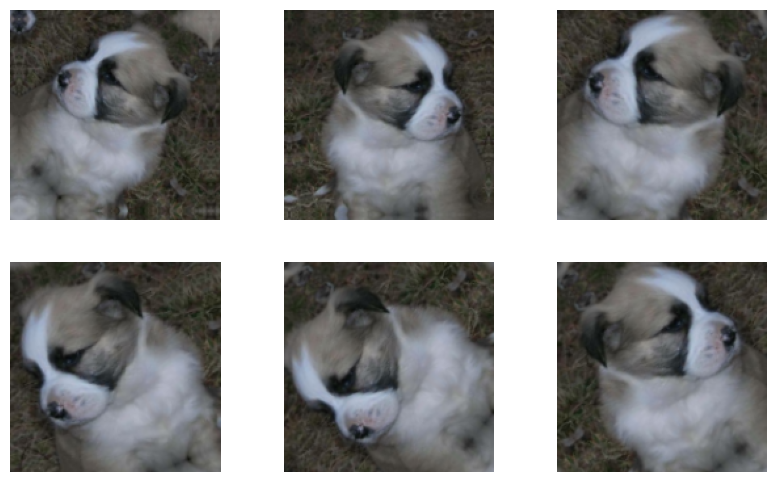

In [ ]:

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.3),
    tf.keras.layers.RandomZoom(0.1),
])

# visualize augmentation
plt.figure(figsize=(10, 6))
for images, _ in train_ds.take(1):
    for i in range(6):
        aug_img = data_augmentation(images)
        ax = plt.subplot(2, 3, i + 1)
        plt.imshow(aug_img[0])
        plt.axis("off")
plt.show()


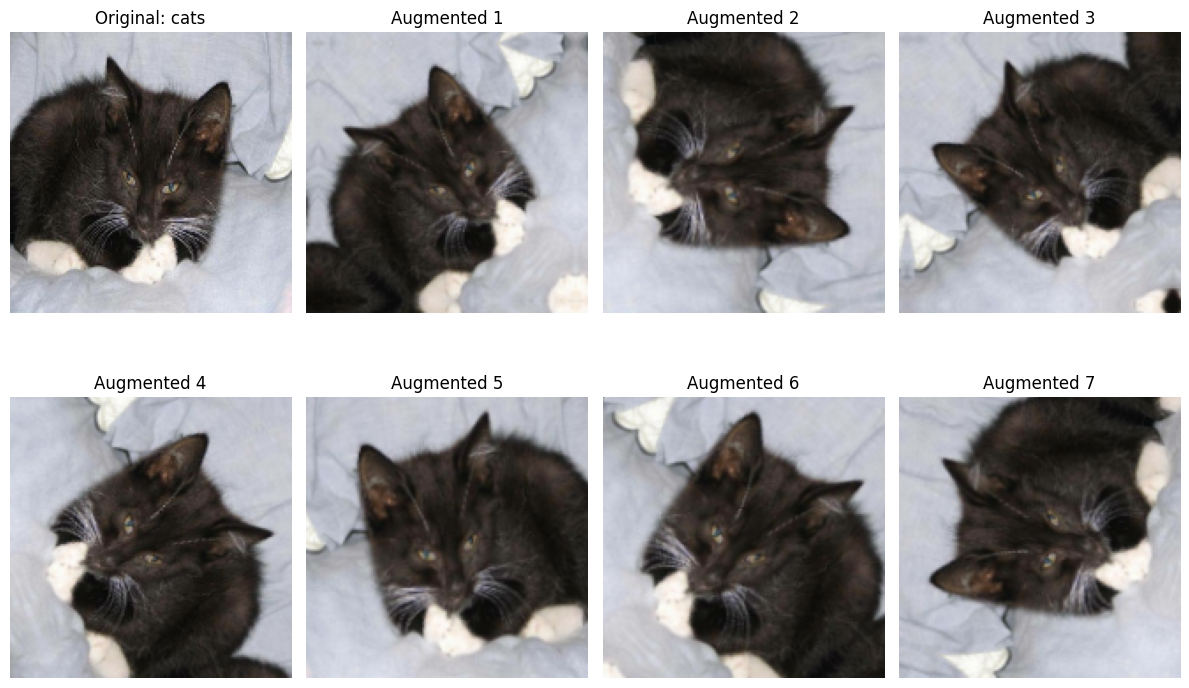

In [ ]:
# take one image
image, label = next(iter(train_ds))

original_image = image[0]
class_id = label[0].numpy()


plt.figure(figsize=(12,8))


# original
plt.subplot(2,4,1)
plt.imshow(original_image.numpy())
plt.title("Original: "+class_names[class_id])
plt.axis("off")


# augmented versions
for i in range(7):

    augmented = data_augmentation(
        tf.expand_dims(original_image,0)
    )[0]

    plt.subplot(2,4,i+2)

    plt.imshow(
        augmented.numpy()
    )

    plt.title(f"Augmented {i+1}")
    plt.axis("off")


plt.tight_layout()
plt.show()

In [ ]:
images[0].shape

TensorShape([160, 160, 3])

## 5. Model Defintions

- Custom CNN Model
- Pretrained CNN Models

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.3),
    tf.keras.layers.RandomZoom(0.1),
])



custom_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(160, 160, 3)),
    data_augmentation,
    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(128, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    # tf.keras.layers.Conv2D(1, (1, 1) activation='sigmoid')  # binary segmentation
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(1, activation="sigmoid") # binary classification  -> 0.5
    # tf.keras.layers.Dense(2, activation="softmax") # multiclass classification -> [0.3, 0.7]
    # cat/dog - binary -

])

custom_model.compile(
    optimizer= 'adam',
    loss='binary_crossentropy',
    loss = 'categorical_crossentropy'
    metrics=['accuracy']
)

custom_model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,401,921 (20.61 MB)

 Trainable params: 5,401,921 (20.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    input_shape=(160,160,3),
    weights='imagenet'
)

base_model.trainable = False

eff_model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

eff_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

eff_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 5, 5, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 6. Callbacks (EarlyStopping)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, monitor='val_loss', min_delta=0.000),
]


## 7. Train Model

- a. Train a custom CNN Model
- b. Finetune a pretrained Model


In [ ]:
history_custom_model = custom_model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=30,
  callbacks=callbacks
)


Epoch 1/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 30s 51ms/step - accuracy: 0.6037 - loss: 0.6630 - val_accuracy: 0.6668 - val_loss: 0.6147
Epoch 2/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 35s 45ms/step - accuracy: 0.6524 - loss: 0.6221 - val_accuracy: 0.6645 - val_loss: 0.6339
Epoch 3/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 46ms/step - accuracy: 0.6852 - loss: 0.5927 - val_accuracy: 0.6693 - val_loss: 0.6106
Epoch 4/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 40s 44ms/step - accuracy: 0.7098 - loss: 0.5648 - val_accuracy: 0.7378 - val_loss: 0.5330
Epoch 5/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 28s 56ms/step - accuracy: 0.7312 - loss: 0.5382 - val_accuracy: 0.7356 - val_loss: 0.5345
Epoch 6/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 27s 54ms/step - accuracy: 0.7387 - loss: 0.5212 - val_accuracy: 0.7641 - val_loss: 0.4880
Epoch 7/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 22s 44ms/step - accuracy: 0.7516 - loss: 0.5056 - val_accuracy: 0.7368 - val_loss: 0.5211
Epoch 8/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 22s 43ms/step - accuracy: 0.7621 - loss: 0.4923 - 

**N.B.** Notice that here training is stopped after 19 epoch because of using Early Stopping.

In [ ]:
history_eff_model = eff_model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=30,
  callbacks=callbacks
)

Epoch 1/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 103s 149ms/step - accuracy: 0.5071 - loss: 0.6995 - val_accuracy: 0.5104 - val_loss: 0.6930
Epoch 2/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 26s 53ms/step - accuracy: 0.4936 - loss: 0.6932 - val_accuracy: 0.4896 - val_loss: 0.6933
Epoch 3/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 51ms/step - accuracy: 0.5029 - loss: 0.6932 - val_accuracy: 0.4896 - val_loss: 0.6933


## 8. Evaluation

In [ ]:
y_true = []
y_pred = []

for images, labels in val_ds:
    preds = custom_model.predict(images)
    y_true.extend(labels.numpy())
    y_pred.extend((preds > 0.5).astype(int).flatten())

print(classification_report(y_true, y_pred, target_names=class_names))


In [ ]:
y_true = []
y_pred = []

for images, labels in val_ds:
    preds = eff_model.predict(images)
    y_true.extend(labels.numpy())
    y_pred.extend((preds > 0.5).astype(int).flatten())

print(classification_report(y_true, y_pred, target_names=class_names))


## 9. Confusion Matrix

In [ ]:

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


## 10. EfficientNet Transfer Learning

## 11. Train EfficientNet

In [ ]:

history2 = eff_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks
)


## 12. Error Analysis (Misclassified Images)

In [ ]:

import matplotlib.pyplot as plt

misclassified = []

for images, labels in val_ds:
    preds = eff_model.predict(images)
    preds = (preds > 0.5).astype(int).flatten()

    for img, true, pred in zip(images, labels.numpy(), preds):
        if true != pred:
            misclassified.append((img, true, pred))

plt.figure(figsize=(10,10))
for i, (img, true, pred) in enumerate(misclassified[:9]):
    ax = plt.subplot(3,3,i+1)
    plt.imshow(img)
    plt.title(f"True:{class_names[true]} Pred:{class_names[pred]}")
    plt.axis("off")
plt.show()
